In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
raw_data_path = "../data/raw/"
orders = pd.read_csv(raw_data_path + "olist_orders_dataset.csv")
items = pd.read_csv(raw_data_path + "olist_order_items_dataset.csv")
customers = pd.read_csv(raw_data_path + "olist_customers_dataset.csv")
products = pd.read_csv(raw_data_path + "olist_products_dataset.csv")

In [3]:
data = {
    "Orders" : orders,
    "Items" : items,
    "Customers" : customers,
    "Products" : products
}

for k, d in data.items():
    print(k)
    print(d.columns)

Orders
Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date'],
      dtype='object')
Items
Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value'],
      dtype='object')
Customers
Index(['customer_id', 'customer_unique_id', 'customer_zip_code_prefix',
       'customer_city', 'customer_state'],
      dtype='object')
Products
Index(['product_id', 'product_category_name', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm'],
      dtype='object')


### Data Sparsity & The "Long Tail"

In [4]:
merged = orders.merge(customers, on="customer_id").merge(items, on="order_id")
num_users = merged['customer_unique_id'].nunique()
num_items = merged['product_id'].nunique()
total_interactions = len(merged)
possible_interactions = num_users * num_items
sparsity = 1 - (total_interactions / possible_interactions)

print(f"Total Unique Users: {num_users}")
print(f"Total Unique Items: {num_items}")
print(f"Total Purchases (Interactions): {total_interactions}")
print(f"Matrix Sparsity: {sparsity * 100:.4f}%")

Total Unique Users: 95420
Total Unique Items: 32951
Total Purchases (Interactions): 112650
Matrix Sparsity: 99.9964%


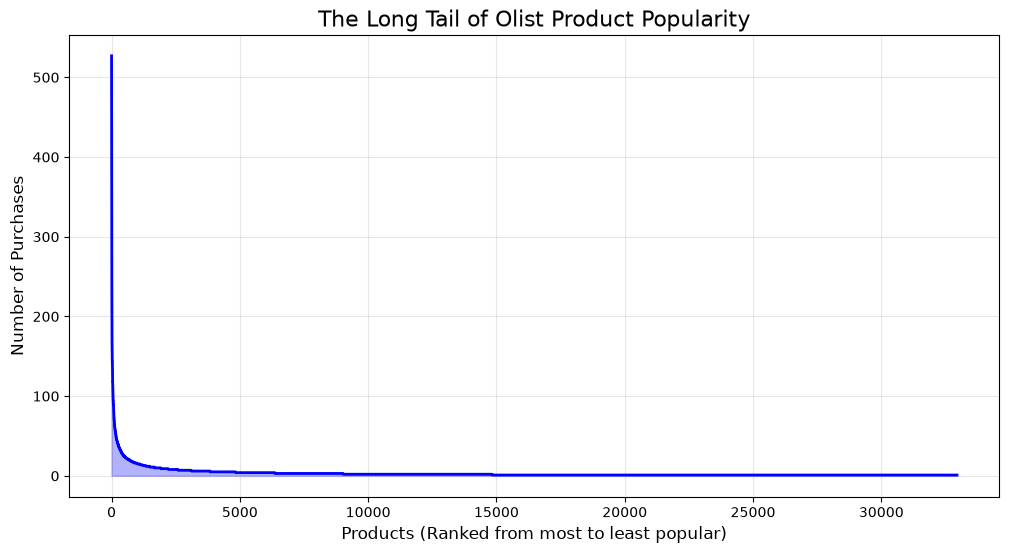

Total Unique Items: 32951
Top 12627 items (38.32% of the catalog) account for 80% of all sales.
The remaining 20324 items make up the massive 'Long Tail'.


In [5]:
# 1. Count how many times each product was bought
item_popularity = merged['product_id'].value_counts()

# 2. Plot the Long Tail
plt.figure(figsize=(12, 6))
plt.plot(item_popularity.values, color='blue', linewidth=2)
plt.fill_between(range(len(item_popularity)), item_popularity.values, color='blue', alpha=0.3)
plt.title('The Long Tail of Olist Product Popularity', fontsize=16)
plt.xlabel('Products (Ranked from most to least popular)', fontsize=12)
plt.ylabel('Number of Purchases', fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()

# 3. Calculate the Pareto Principle (80/20 Rule)
cumulative_sales = item_popularity.cumsum()
total_sales = item_popularity.sum()
cumulative_percentage = cumulative_sales / total_sales

# Find how many items it takes to reach 80% of total sales
items_80_percent = len(cumulative_percentage[cumulative_percentage <= 0.8])
percent_catalog_80_sales = (items_80_percent / len(item_popularity)) * 100

print(f"Total Unique Items: {len(item_popularity)}")
print(f"Top {items_80_percent} items ({percent_catalog_80_sales:.2f}% of the catalog) account for 80% of all sales.")
print(f"The remaining {len(item_popularity) - items_80_percent} items make up the massive 'Long Tail'.")